# Final — four findings from the Hacker News case study
**A concise presentation of the historical experiment · 6 figures**

We study whether monitoring a small set of users can reveal significant observed discussions early,
and whether CELF adds value beyond simple rankings.

**Scope:** These headline detection results are **retrospective and in-sample**: users were selected and
evaluated on the same retained data. A significant discussion means **at least 10 distinct retained repliers**;
the benchmark contains **3,418** such discussions. Times are measured from the first retained reply,
not necessarily the true start of the discussion. Read the short validation note at the end before quoting superiority claims.

Run the cells in order with the existing project `venv`. The notebook reads original files and writes only to
`final_assets/`. The setup verifies the numbers; each following code cell produces exactly one figure.


### Evidence setup
**What and why:** Reconstruct observed discussion participation and timing; verify the saved 20-sensor
result and Top-reach ranking against the raw records. Read the archived influence comparison and check
the independent validation figures. This prevents manually chosen headline numbers from entering the charts.


In [1]:
from pathlib import Path
from collections import defaultdict
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
get_ipython().run_line_magic('matplotlib','inline')
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/detection_results.csv').exists())
OUT=ROOT/'final_assets'; OUT.mkdir(exist_ok=True)
inputs=['data/hn_interactions_v3_CLEAN.csv','data/detection_results.csv','data/detection_summary.json',
        'username_mapping_v3_PRIVATE.json','im_results.csv','experiment_summary.json',
        'completion_outputs/test_detection_results.csv']
def digest(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(1024*1024),b''):h.update(b)
    return h.hexdigest()
hashes={p:digest(ROOT/p) for p in inputs}
det=pd.read_csv(ROOT/'data/detection_results.csv')
im=pd.read_csv(ROOT/'im_results.csv')
summary=json.loads((ROOT/'data/detection_summary.json').read_text())
experiment=json.loads((ROOT/'experiment_summary.json').read_text())
holdout=pd.read_csv(ROOT/'completion_outputs/test_detection_results.csv')
raw=pd.read_csv(ROOT/'data/hn_interactions_v3_CLEAN.csv',
    usecols=['story_id','timestamp_utc','target_user_hash','replier_username'])
raw['seconds']=pd.to_datetime(raw.timestamp_utc,utc=True).dt.as_unit('ns').astype('int64')/1e9
arrival=defaultdict(dict);half={};lifetimes=[]
# Preserve the historical notebook's story order and arrival tie order.
for sid,g in raw.groupby('story_id',sort=False):
    if g.target_user_hash.nunique()<10:continue
    g=g.sort_values(['seconds','replier_username'])
    start=g.seconds.iloc[0];lifetimes.append((g.seconds.iloc[-1]-start)/3600)
    half[sid]=(g.seconds.iloc[len(g)//2]-start)/3600
    for row in g.itertuples():arrival[row.target_user_hash].setdefault(sid,(row.seconds-start)/3600)
mapping=json.loads((ROOT/'username_mapping_v3_PRIVATE.json').read_text())
reverse={v:k for k,v in mapping.items()}
sensors=[reverse[u] for u in summary['sensors']]
top=sorted(arrival,key=lambda u:-len(arrival[u]))[:20]
def coverage(S):return set().union(*(set(arrival[u]) for u in S))
covered=coverage(sensors);top_covered=coverage(top);n=len(half)
delays={s:min(arrival[u][s] for u in sensors if s in arrival[u]) for s in covered}
median_delay=float(np.median(list(delays.values())))
before_half=float(np.mean([delays[s]<half[s] for s in covered]))
median_life=float(np.median(lifetimes))
overlap=lambda S:1-len(coverage(S))/sum(len(arrival[u]) for u in S)
celf_overlap=overlap(sensors);top_overlap=overlap(top)
d20=det[det.k==20].set_index('algorithm')
random_rate=float(d20.loc['Random','detection_rate'])
relative_gain=(len(covered)/len(top_covered)-1)*100
gvc=experiment['greedy_vs_celf'];work_ratio=gvc['greedy_evals']/gvc['celf_evals']
d30=det[det.k==30].set_index('algorithm');i30=im[im.k==30].set_index('algorithm')
detect_gain30=100*(d30.loc['CELF-detect','detection_rate']/d30.loc['Top-reach','detection_rate']-1)
influence_gain30=100*(i30.loc['CELF','spread']/i30.loc['Degree','spread']-1)
test20=holdout[holdout.k==20].set_index('method')
assert n==3418 and len(sensors)==20 and len(covered)==1781 and len(top_covered)==1585
assert np.isclose(len(covered)/n,d20.loc['CELF-detect','detection_rate'])
assert np.isclose(len(top_covered)/n,d20.loc['Top-reach','detection_rate'])
assert np.isclose(median_delay,summary['median_delay_h'])
assert np.isclose(before_half*100,summary['pct_before_half'])
assert gvc['identical'] is True and gvc['k']==5
evidence={'outbreaks':n,'sensors':20,'celf_detected':len(covered),'top_reach_detected':len(top_covered),
 'random_rate_saved_10_draw_mean':random_rate,'median_delay_detected_h':median_delay,
 'median_observed_lifespan_all_outbreaks_h':median_life,'before_half_among_detected':before_half,
 'celf_overlap':celf_overlap,'top_reach_overlap':top_overlap,'relative_detection_gain_k20_pct':relative_gain,
 'greedy_celf_evaluation_ratio_k5':work_ratio,'influence_gain_vs_degree_k30_pct':influence_gain30,
 'detection_gain_vs_top_reach_k30_pct':detect_gain30,
 'heldout_celf_k20':float(test20.loc['CELF-detect','detection_rate']),
 'heldout_top_reach_k20':float(test20.loc['Top-reach','detection_rate'])}
(OUT/'verified_numbers.json').write_text(json.dumps(evidence,indent=2))
(OUT/'source_hashes.json').write_text(json.dumps(hashes,indent=2))
BLUE='#235E79';TEAL='#188575';GRAY='#8B98A5';INK='#203445';PAPER='#FAFCFD'
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.titlesize':17,
    'axes.titleweight':'bold','axes.labelcolor':INK,'text.color':INK,'axes.spines.top':False,
    'axes.spines.right':False,'figure.facecolor':PAPER,'axes.facecolor':PAPER,'savefig.facecolor':PAPER})
def finish(fig,name,caption):
    fig.text(.05,.025,caption,ha='left',va='bottom',fontsize=9,color='#536879')
    fig.tight_layout(rect=[.02,.12,.98,.98])
    fig.savefig(OUT/(name+'.png'),dpi=180,bbox_inches='tight')
    plt.show();plt.close(fig)
# Raw usernames are needed only to reproduce historical tie ordering; never display them.
del raw,mapping,reverse


## 1. A small monitored group detected emerging discussions early
Twenty selected users detected **52.1%** of significant observed discussions, compared with **14.1%**
for the saved random baseline: **3.69× the coverage**.

**Figure 1 — purpose:** Compare coverage at the same 20-user budget. Random is the historical mean of
10 draws, not a single hand-picked draw; the chart does not claim statistical certainty from that mean.


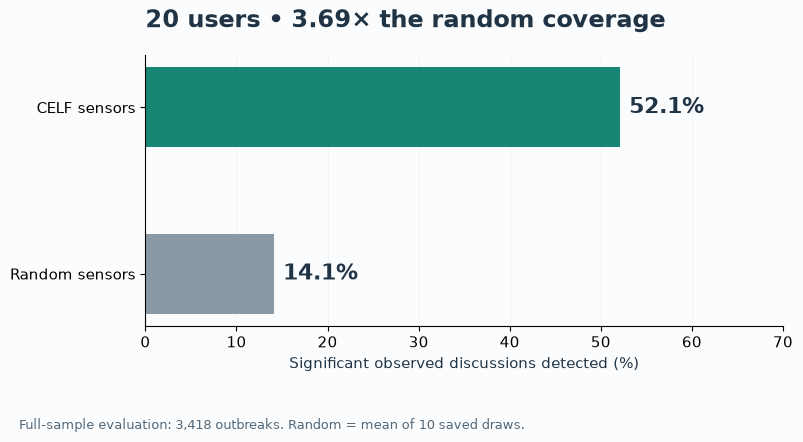

In [2]:
fig,ax=plt.subplots(figsize=(8.5,4.6))
values=[100*len(covered)/n,100*random_rate]
bars=ax.barh(['CELF sensors','Random sensors'],values,color=[TEAL,GRAY],height=.48)
ax.invert_yaxis();ax.set_xlim(0,70);ax.set_xlabel('Significant observed discussions detected (%)')
ax.set_title('20 users • 3.69× the random coverage',loc='left',pad=20)
for bar,v in zip(bars,values):ax.text(v+1,bar.get_y()+bar.get_height()/2,f'{v:.1f}%',va='center',weight='bold',fontsize=16)
ax.grid(axis='x',alpha=.13);ax.set_axisbelow(True)
finish(fig,'01_detection_coverage','Full-sample evaluation: 3,418 outbreaks. Random = mean of 10 saved draws.')


**Figure 2 — purpose:** Put detection speed in context. The **2.63-hour median delay** is among
detected outbreaks; the **56.38-hour median observed lifespan** is across all outbreaks. These are
different denominators. **77.6% of detected outbreaks** were flagged before half their retained replies
had occurred—not before half their elapsed duration or before a measured activity peak.


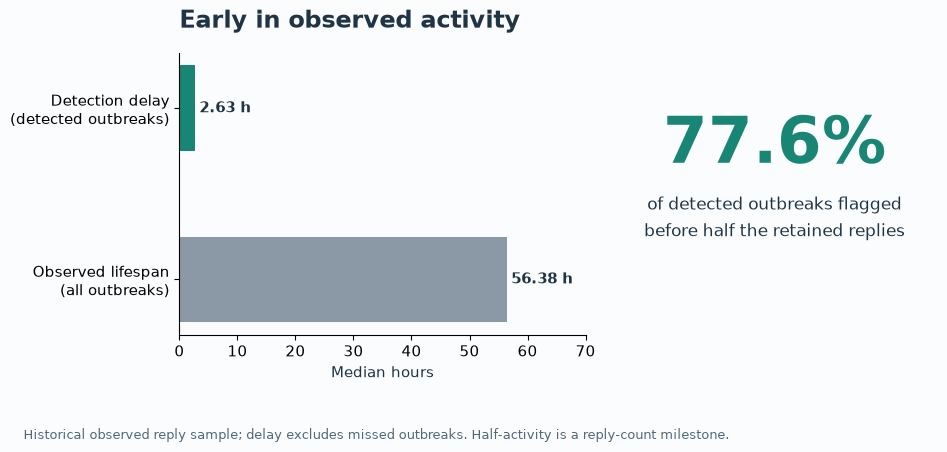

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4.7),gridspec_kw={'width_ratios':[1.25,1]})
ax=axes[0];vals=[median_delay,median_life]
bars=ax.barh(['Detection delay\n(detected outbreaks)','Observed lifespan\n(all outbreaks)'],vals,color=[TEAL,GRAY],height=.5)
ax.invert_yaxis();ax.set_xlim(0,70);ax.set_xlabel('Median hours');ax.set_title('Early in observed activity',loc='left',pad=18)
for b,v in zip(bars,vals):ax.text(v+.8,b.get_y()+b.get_height()/2,f'{v:.2f} h',va='center',weight='bold')
axes[1].axis('off');axes[1].text(.5,.61,f'{100*before_half:.1f}%',ha='center',fontsize=46,weight='bold',color=TEAL)
axes[1].text(.5,.35,'of detected outbreaks flagged\nbefore half the retained replies',ha='center',fontsize=12,linespacing=1.6)
finish(fig,'02_early_detection','Historical observed reply sample; delay excludes missed outbreaks. Half-activity is a reply-count milestone.')


## 2. CELF added coverage beyond the obvious activity ranking
At 20 sensors, CELF detected **1,781** outbreaks versus **1,585** for Top-reach:
**196 additional outbreaks**, a **12.4% relative improvement** (5.7 percentage points of coverage).
Top-reach means users active in the most outbreak discussions; it is not a ranking by total comment volume.

**Figure 3 — purpose:** Show the actual counts behind the percentage improvement, on the same benchmark.


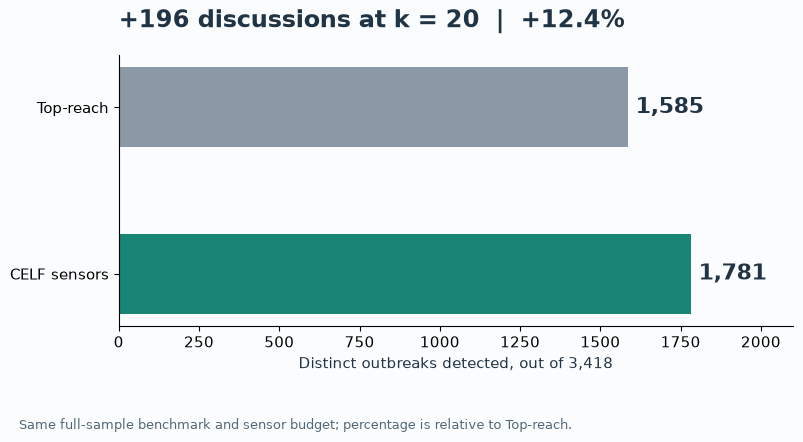

In [4]:
fig,ax=plt.subplots(figsize=(8.5,4.6));vals=[len(top_covered),len(covered)]
bars=ax.barh(['Top-reach','CELF sensors'],vals,color=[GRAY,TEAL],height=.48)
ax.invert_yaxis();ax.set_xlim(0,2100);ax.set_xlabel('Distinct outbreaks detected, out of 3,418')
ax.set_title(f'+{len(covered)-len(top_covered)} discussions at k = 20  |  +{relative_gain:.1f}%',loc='left',pad=20)
for b,v in zip(bars,vals):ax.text(v+25,b.get_y()+b.get_height()/2,f'{v:,}',va='center',fontsize=16,weight='bold')
finish(fig,'03_incremental_coverage','Same full-sample benchmark and sensor budget; percentage is relative to Top-reach.')


**Figure 4 — purpose:** Quantify repeated coverage within each selected set. Overlap is
`1 − distinct outbreaks covered / sum of each sensor’s individual outbreak coverage`.
It was **60.7% for Top-reach versus 48.6% for CELF**. This is consistent with selecting complementary
users; it is not a separate causal proof that overlap alone produced the coverage gain.


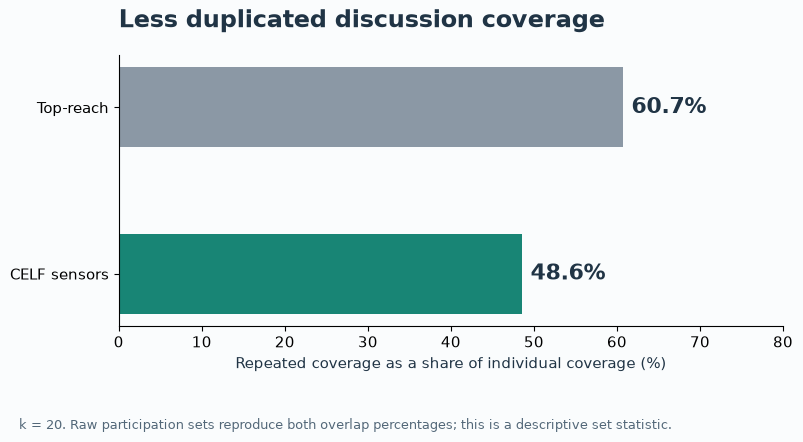

In [5]:
fig,ax=plt.subplots(figsize=(8.5,4.6));vals=[100*top_overlap,100*celf_overlap]
bars=ax.barh(['Top-reach','CELF sensors'],vals,color=[GRAY,TEAL],height=.48)
ax.invert_yaxis();ax.set_xlim(0,80);ax.set_xlabel('Repeated coverage as a share of individual coverage (%)')
ax.set_title('Less duplicated discussion coverage',loc='left',pad=20)
for b,v in zip(bars,vals):ax.text(v+1,b.get_y()+b.get_height()/2,f'{v:.1f}%',va='center',fontsize=16,weight='bold')
finish(fig,'04_coverage_overlap','k = 20. Raw participation sets reproduce both overlap percentages; this is a descriptive set statistic.')


## 3. CELF matched greedy while evaluating fewer candidates
The saved production influence experiment at **k = 5** reports **the same ordered seed selection**
for CELF and ordinary greedy, with **2,527 versus 9,990 objective evaluations**: **3.95× fewer evaluations**.

**Figure 5 — purpose:** Demonstrate lazy evaluation’s computational benefit on the recorded instance.
Ordinary greedy checks each remaining candidate at each step; it is **not exhaustive search over all seed sets**.
Agreement supports implementation correctness. It does not prove the theorem, global optimality, or a speedup
in wall-clock time equal to the evaluation ratio.

The theoretical greedy approximation bound requires a normalized, nonnegative, monotone submodular
objective. The corrected clipped detection objective and fixed-world influence tests are documented in
`PROJECT_COMPLETION.ipynb`; the historical unclipped detection implementation should not be used as proof of that guarantee.


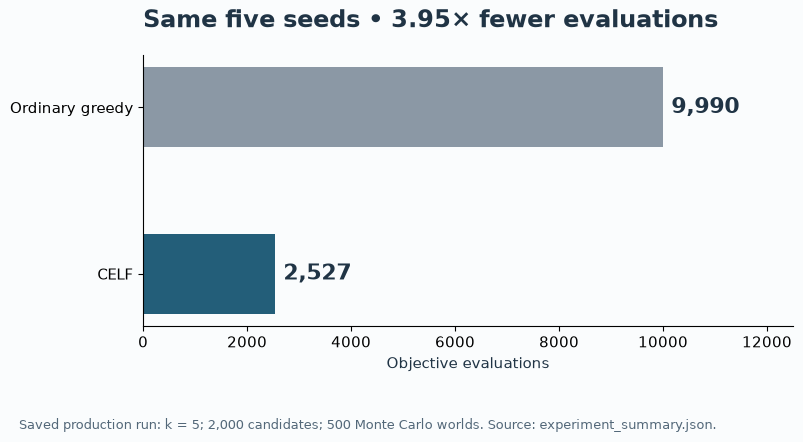

In [6]:
fig,ax=plt.subplots(figsize=(8.5,4.6));vals=[gvc['greedy_evals'],gvc['celf_evals']]
bars=ax.barh(['Ordinary greedy','CELF'],vals,color=[GRAY,BLUE],height=.48)
ax.invert_yaxis();ax.set_xlim(0,12500);ax.set_xlabel('Objective evaluations')
ax.set_title(f'Same five seeds • {work_ratio:.2f}× fewer evaluations',loc='left',pad=20)
for b,v in zip(bars,vals):ax.text(v+170,b.get_y()+b.get_height()/2,f'{v:,}',va='center',fontsize=16,weight='bold')
finish(fig,'05_greedy_celf_work','Saved production run: k = 5; 2,000 candidates; 500 Monte Carlo worlds. Source: experiment_summary.json.')


## 4. The observed benefit depended on the task and baseline
At the same **k = 30** budget, the historical influence comparison gained **0.53% over Degree**,
while detection gained **13.1% over Top-reach**. This motivates choosing the optimization objective
to match the application. It is a descriptive comparison of two experiments—not a controlled experiment
isolating the objective as the only difference. Their baselines, candidate pools and evaluation measures differ.

**Figure 6 — purpose:** Compare relative gains at a matched budget without mixing k = 20 and k = 30.
The influence outcome is simulated spread; the detection outcome is coverage of observed discussions.


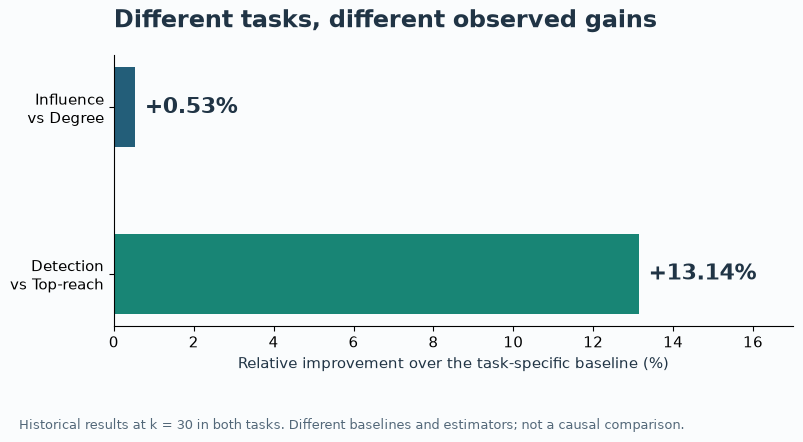

In [7]:
fig,ax=plt.subplots(figsize=(8.5,4.6));vals=[influence_gain30,detect_gain30]
bars=ax.barh(['Influence\nvs Degree','Detection\nvs Top-reach'],vals,color=[BLUE,TEAL],height=.48)
ax.invert_yaxis();ax.set_xlim(0,17);ax.set_xlabel('Relative improvement over the task-specific baseline (%)')
ax.set_title('Different tasks, different observed gains',loc='left',pad=20)
for b,v in zip(bars,vals):ax.text(v+.25,b.get_y()+b.get_height()/2,f'+{v:.2f}%',va='center',fontsize=16,weight='bold')
finish(fig,'06_task_comparison','Historical results at k = 30 in both tasks. Different baselines and estimators; not a causal comparison.')
assert all(digest(ROOT/p)==v for p,v in hashes.items()),'A source file changed.'
assert len(list(OUT.glob('0*.png')))==6


### Validation note — the boundary of these four findings
The headline detection figures above establish **historical in-sample performance**, not future superiority.
In the separate chronological held-out evaluation at 20 sensors, **CELF detected 26.8% versus 45.6% for
Top-reach**. Therefore, the defensible conclusion is that CELF improved coverage in the original retrospective
experiment; that advantage did **not** generalize in the tested time split. This qualification is essential when
presenting the project as a completed evaluation.

### Evidence trail
- **Figures 1–4:** `data/detection_results.csv`, `data/detection_summary.json` and raw retained interactions.
  Coverage, timing, baseline membership and overlap are checked in this notebook. Random is the saved 10-draw mean.
- **Figure 5:** `experiment_summary.json` and the historical `influence_maximization_HN.ipynb` experiment.
  The verified production ratio replaces the earlier 2.3× draft figure.
- **Figure 6:** `im_results.csv` and `data/detection_results.csv`, both at k = 30.
- **Validation:** `completion_outputs/test_detection_results.csv`; full protocol in `PROJECT_COMPLETION.ipynb`.
- **Exports:** Six presentation-ready PNGs, verified values and source hashes in `final_assets/`.

All six visuals have a defined denominator, budget and evidence source. No claim of exhaustive optimality,
causal influence, complete platform coverage or prospective operational performance is needed to present these findings.
